In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv("dataset/campus_complaints_dataset.csv")

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Total Rows: 1500
Total Columns: 15


,complaint_id,student_id,date_submitted,submitted_hour,category,location,description,has_media,priority,status,assigned_to,date_assigned,date_resolved,resolution_days,feedback_rating
0,CMP0001,23001001143,02-01-2025,17,Cleaning,Hostel B,Cobwebs and stains on walls,1,Medium,Resolved,Housekeeping,02-01-2025,03-01-2025,1.0,5.0
1,CMP0002,24001001328,02-01-2025,15,Plumbing,Hostel A,"Problem in the room, please check",1,Low,Resolved,Plumbing Team,03-01-2025,08-01-2025,6.0,4.0
2,CMP0003,23001001166,02-01-2025,22,Cleaning,Hostel C,Mosquitoes and insects in the area,1,High,Resolved,Housekeeping,02-01-2025,03-01-2025,1.0,4.0
3,CMP0004,23001001289,03-01-2025,13,Furniture,Hostel B,Curtain rod fell down,0,Low,Resolved,Carpenter Unit,04-01-2025,13-01-2025,10.0,5.0
4,CMP0005,24001001081,03-01-2025,20,Plumbing,Hostel C,Paani nahi aa raha tap mein,0,High,Closed,Plumbing Team,03-01-2025,05-01-2025,2.0,NaN


In [8]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   complaint_id     1500 non-null   object 
 1   student_id       1500 non-null   int64  
 2   date_submitted   1500 non-null   object 
 3   submitted_hour   1500 non-null   int64  
 4   category         1500 non-null   object 
 5   location         1500 non-null   object 
 6   description      1500 non-null   object 
 7   has_media        1500 non-null   int64  
 8   priority         1500 non-null   object 
 9   status           1500 non-null   object 
 10  assigned_to      1500 non-null   object 
 11  date_assigned    1499 non-null   object 
 12  date_resolved    1418 non-null   object 
 13  resolution_days  1418 non-null   float64
 14  feedback_rating  1017 non-null   float64
dtypes: float64(2), int64(3), object(10)
memory usage: 175.9+ KB


In [11]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
complaint_id,1500,1500,CMP1500,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
student_id,1500.0,NaN,NaN,NaN,23984334532.661999,816190133.721373,23001001006.0,23001001291.0,24001001192.0,25001001101.0,25001001399.0
date_submitted,1500,592,17-04-2025,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
submitted_hour,1500.0,NaN,NaN,NaN,15.069333,4.629631,7.0,11.0,15.0,19.0,23.0
category,1500,7,Electrical,269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,1500,12,Hostel B,245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,1500,108,"Problem in the room, please check",32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_media,1500.0,NaN,NaN,NaN,0.527333,0.499419,0.0,0.0,1.0,1.0,1.0
priority,1500,3,Medium,640,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,1500,5,Resolved,807,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing[missing["Missing Values"] > 0])

,Missing Values,Missing Percentage
date_assigned,1,0.07
date_resolved,82,5.47
resolution_days,82,5.47
feedback_rating,483,32.20


In [13]:
print("Duplicate Records:", df.duplicated().sum())
print("Unique Complaint IDs:", df["complaint_id"].nunique())

Duplicate Records: 0
Unique Complaint IDs: 1500


In [14]:
df.shape

(1500, 15)

Complaint Category Distribution


category
Electrical    269
Cleaning      252
IT/Network    251
Plumbing      239
Civil         212
Furniture     165
Security      112
Name: count, dtype: int64

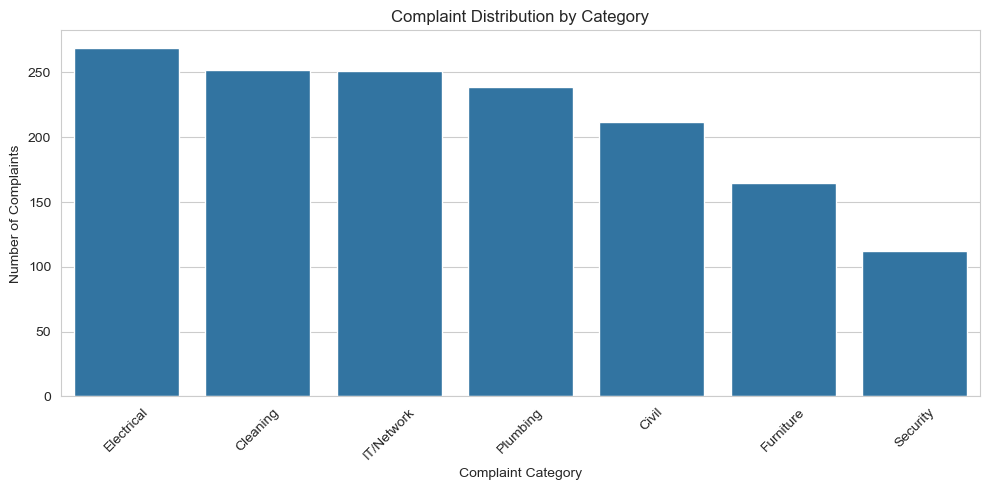

In [15]:
print("Complaint Category Distribution")

display(df["category"].value_counts())

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Complaint Distribution by Category")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Complaint Priority Distribution


priority
Medium    640
High      457
Low       403
Name: count, dtype: int64

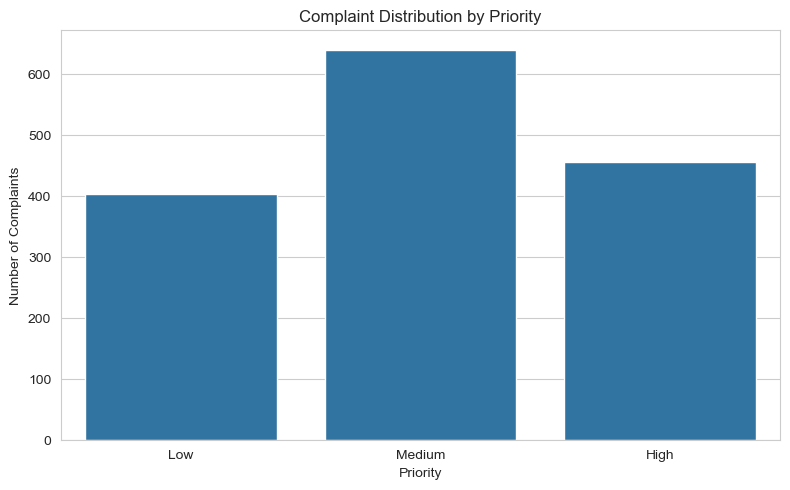

In [16]:
print("Complaint Priority Distribution")

display(df["priority"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="priority",
    order=["Low", "Medium", "High"]
)

plt.title("Complaint Distribution by Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

Complaint Status Distribution


status
Resolved       807
Closed         611
In Progress     76
Assigned         5
Submitted        1
Name: count, dtype: int64

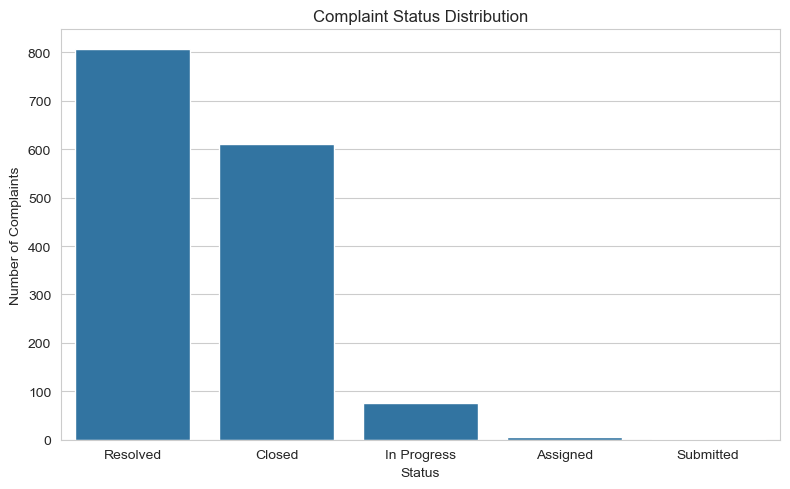

In [17]:
print("Complaint Status Distribution")

display(df["status"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="status",
    order=df["status"].value_counts().index
)

plt.title("Complaint Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

Complaints by Location


location
Hostel B                245
Academic Block          245
Hostel A                196
Hostel C                190
Laboratory Block        161
Computer Center          95
Cafeteria                88
Library                  87
Sports Complex           61
Administrative Block     51
Parking Area             44
Main Gate                37
Name: count, dtype: int64

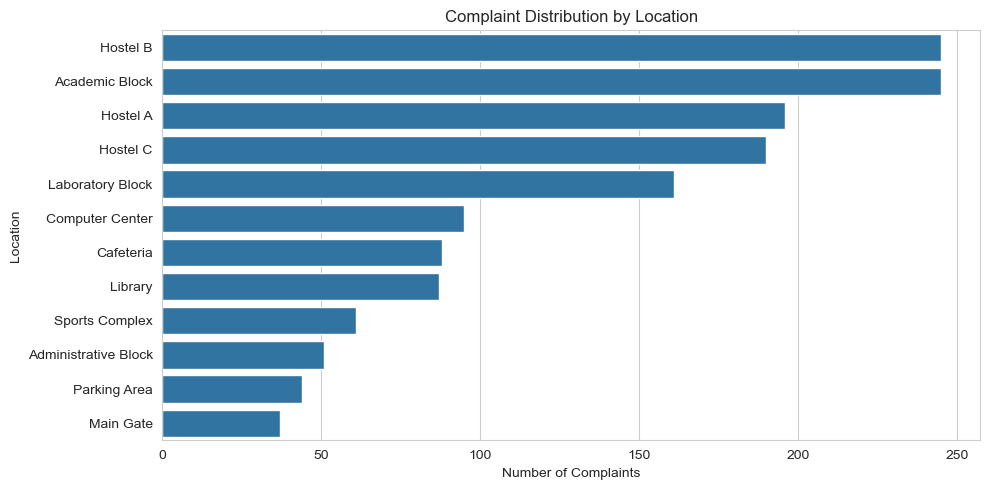

In [18]:
print("Complaints by Location")

display(df["location"].value_counts())

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="location",
    order=df["location"].value_counts().index
)

plt.title("Complaint Distribution by Location")
plt.xlabel("Number of Complaints")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

priority,High,Low,Medium
category,,,
Civil,70,57,85
Cleaning,44,91,117
Electrical,93,71,105
Furniture,24,61,80
IT/Network,86,58,107
Plumbing,90,50,99
Security,50,15,47


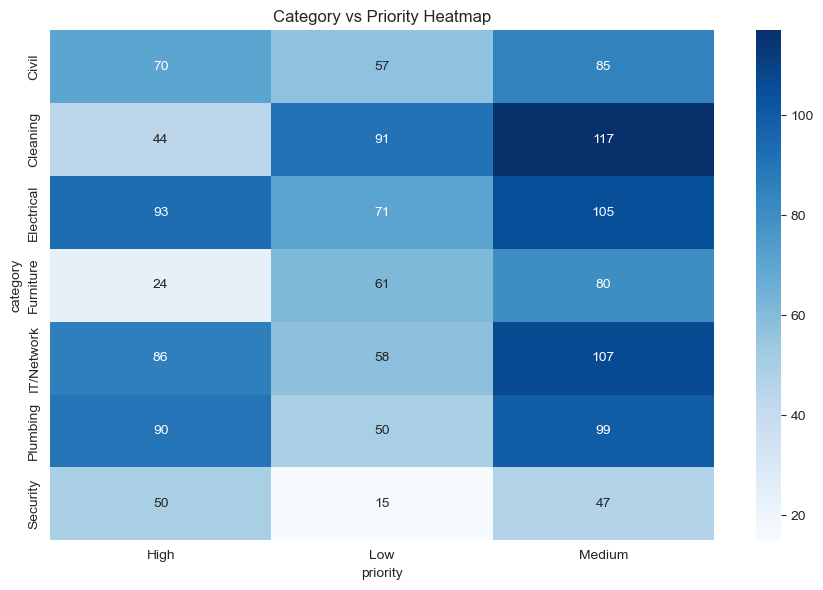

In [19]:
category_priority = pd.crosstab(
    df["category"],
    df["priority"]
)

display(category_priority)

plt.figure(figsize=(9, 6))

sns.heatmap(
    category_priority,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Category vs Priority Heatmap")
plt.tight_layout()
plt.show()

Average Resolution Time: 4.49 days
Median Resolution Time: 3.0 days


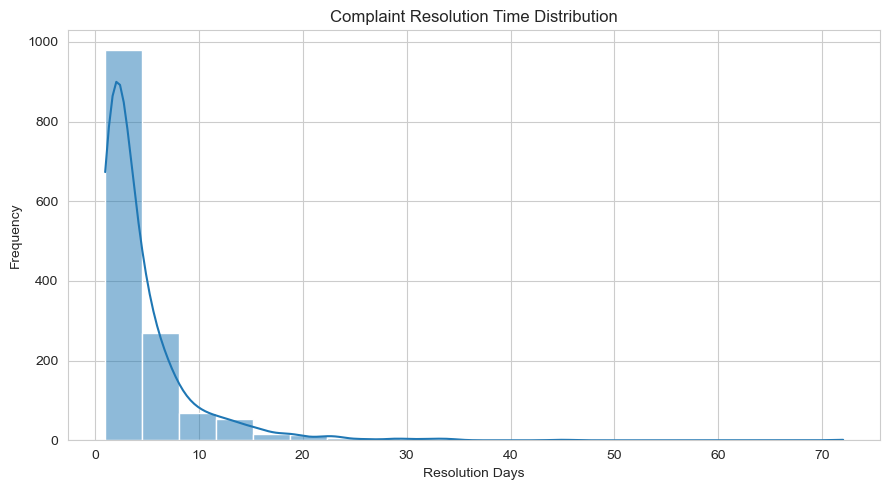

In [20]:
resolved_df = df.dropna(subset=["resolution_days"])

print("Average Resolution Time:",
      round(resolved_df["resolution_days"].mean(), 2), "days")

print("Median Resolution Time:",
      resolved_df["resolution_days"].median(), "days")

plt.figure(figsize=(9, 5))

sns.histplot(
    data=resolved_df,
    x="resolution_days",
    bins=20,
    kde=True
)

plt.title("Complaint Resolution Time Distribution")
plt.xlabel("Resolution Days")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [21]:
df["date_submitted"] = pd.to_datetime(
    df["date_submitted"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["month"] = df["date_submitted"].dt.month_name()
df["day_name"] = df["date_submitted"].dt.day_name()

df[["date_submitted", "month", "day_name"]].head()

,date_submitted,month,day_name
0,2025-01-02,January,Thursday
1,2025-01-02,January,Thursday
2,2025-01-02,January,Thursday
3,2025-01-03,January,Friday
4,2025-01-03,January,Friday


date_submitted
2025-01     61
2025-02     53
2025-03     86
2025-04     79
2025-05     69
2025-06     37
2025-07     54
2025-08     69
2025-09     57
2025-10    105
2025-11     73
2025-12     65
2026-01     62
2026-02     64
2026-03     71
2026-04     55
2026-05     58
2026-06     50
2026-07     99
2026-08     70
2026-09     71
2026-10     66
2026-11     26
Freq: M, dtype: int64

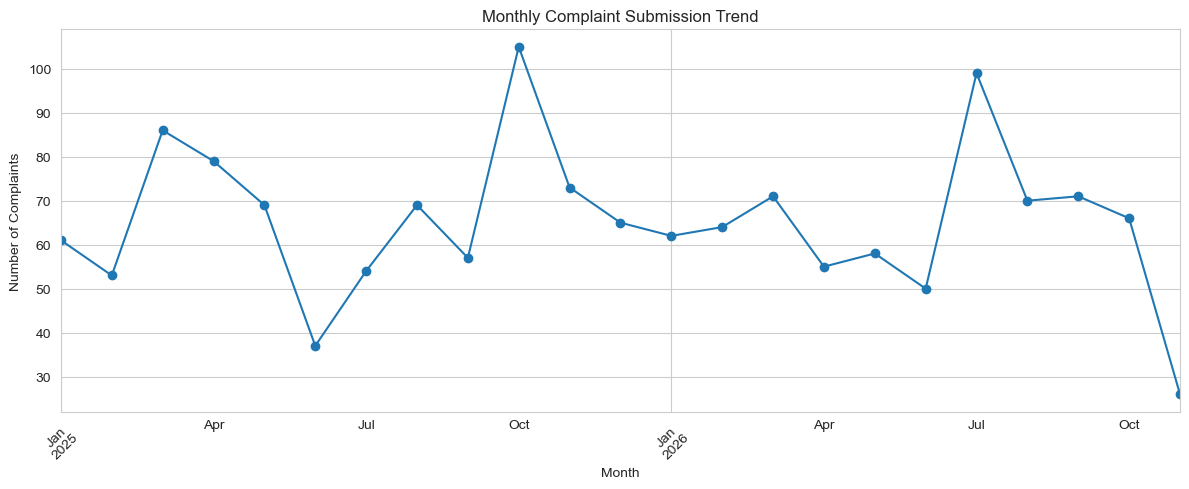

In [22]:
monthly_complaints = (
    df.groupby(df["date_submitted"].dt.to_period("M"))
      .size()
)

display(monthly_complaints)

monthly_complaints.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Monthly Complaint Submission Trend")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

submitted_hour
7      52
8      50
9      84
10    105
11     96
12    120
13    115
14    119
15    102
16     98
17     75
18     72
19     86
20     76
21     66
22     64
23    120
Name: count, dtype: int64

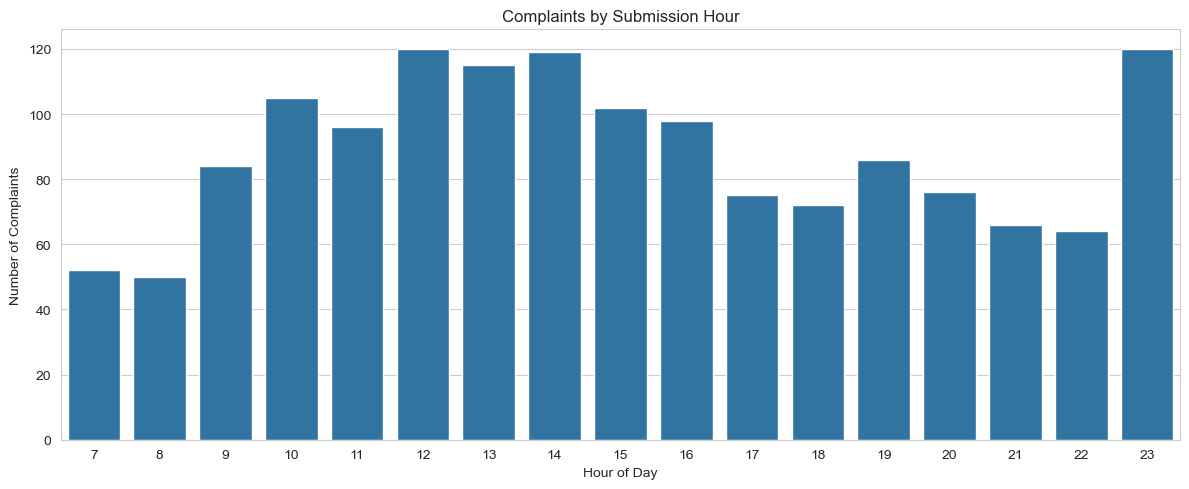

In [23]:
hourly_complaints = df["submitted_hour"].value_counts().sort_index()

display(hourly_complaints)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_complaints.index,
    y=hourly_complaints.values
)

plt.title("Complaints by Submission Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

day_name
Monday       233
Tuesday      227
Wednesday    225
Thursday     227
Friday       217
Saturday     228
Sunday       143
Name: count, dtype: int64

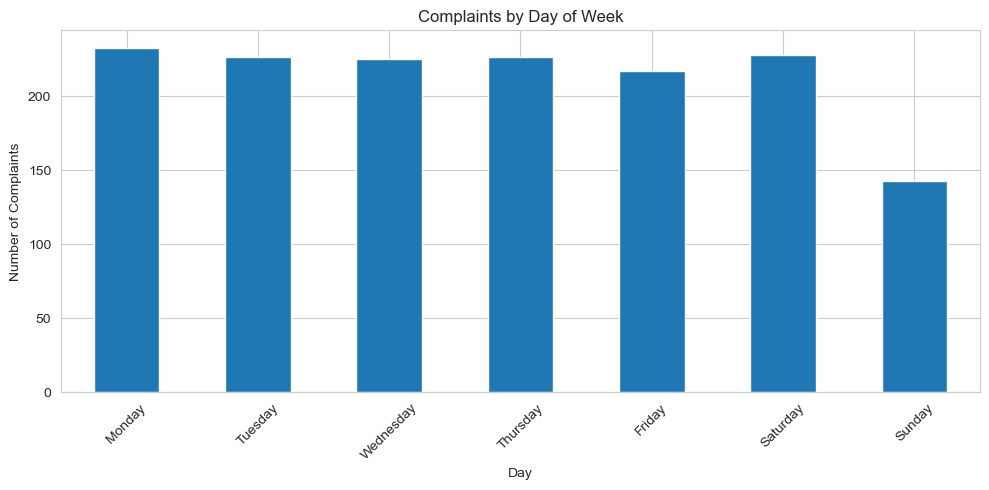

In [24]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_counts = df["day_name"].value_counts().reindex(day_order)

display(day_counts)

day_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Complaints by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
data = df.copy()

print("Original Shape:", df.shape)
print("Working Dataset Shape:", data.shape)

Original Shape: (1500, 17)
Working Dataset Shape: (1500, 17)


In [26]:
print("Data Types:")
display(data.dtypes)

print("\nMissing Values:")
display(data.isnull().sum())

print("\nDuplicate Records:")
print(data.duplicated().sum())

Data Types:


complaint_id               object
student_id                  int64
date_submitted     datetime64[ns]
submitted_hour              int64
category                   object
location                   object
description                object
has_media                   int64
priority                   object
status                     object
assigned_to                object
date_assigned              object
date_resolved              object
resolution_days           float64
feedback_rating           float64
month                      object
day_name                   object
dtype: object


Missing Values:


complaint_id         0
student_id           0
date_submitted       0
submitted_hour       0
category             0
location             0
description          0
has_media            0
priority             0
status               0
assigned_to          0
date_assigned        1
date_resolved       82
resolution_days     82
feedback_rating    483
month                0
day_name             0
dtype: int64


Duplicate Records:
0


In [27]:
print("Invalid submitted hours:",
      (~data["submitted_hour"].between(0, 23)).sum())

print("Invalid feedback ratings:",
      (~data["feedback_rating"].dropna().between(1, 5)).sum())

print("Negative resolution days:",
      (data["resolution_days"].dropna() < 0).sum())

print("\nUnique Categories:")
print(data["category"].unique())

print("\nUnique Priorities:")
print(data["priority"].unique())

print("\nUnique Statuses:")
print(data["status"].unique())

Invalid submitted hours: 0
Invalid feedback ratings: 0
Negative resolution days: 0

Unique Categories:
['Cleaning' 'Plumbing' 'Furniture' 'Security' 'Electrical' 'IT/Network'
 'Civil']

Unique Priorities:
['Medium' 'Low' 'High']

Unique Statuses:
['Resolved' 'Closed' 'In Progress' 'Assigned' 'Submitted']


In [28]:
display(
    data.groupby("status").agg(
        total_complaints=("complaint_id", "count"),
        missing_resolution_date=("date_resolved", "count"),
        missing_resolution_days=("resolution_days", "count"),
        missing_feedback=("feedback_rating",
                          lambda x: x.isna().sum())
    )
)

,total_complaints,missing_resolution_date,missing_resolution_days,missing_feedback
status,,,,
Assigned,5,0,0,5
Closed,611,611,611,173
In Progress,76,0,0,76
Resolved,807,807,807,228
Submitted,1,0,0,1


In [29]:
missing_analysis = data.groupby("status").agg(
    total_complaints=("complaint_id", "count"),
    missing_resolution_date=("date_resolved",
                             lambda x: x.isna().sum()),
    missing_resolution_days=("resolution_days",
                             lambda x: x.isna().sum()),
    missing_feedback=("feedback_rating",
                      lambda x: x.isna().sum())
)

display(missing_analysis)

,total_complaints,missing_resolution_date,missing_resolution_days,missing_feedback
status,,,,
Assigned,5,5,5,5
Closed,611,0,0,173
In Progress,76,76,76,76
Resolved,807,0,0,228
Submitted,1,1,1,1


In [30]:
print("Duplicate Rows:", data.duplicated().sum())

print("\nMissing Values:")
display(data.isnull().sum())

print("\nUnique Complaint IDs:",
      data["complaint_id"].nunique())

Duplicate Rows: 0

Missing Values:


complaint_id         0
student_id           0
date_submitted       0
submitted_hour       0
category             0
location             0
description          0
has_media            0
priority             0
status               0
assigned_to          0
date_assigned        1
date_resolved       82
resolution_days     82
feedback_rating    483
month                0
day_name             0
dtype: int64


Unique Complaint IDs: 1500


In [31]:
pd.set_option("display.max_colwidth", 150)

display(
    data[["description", "category", "priority"]].sample(
        10, random_state=42
    )
)

,description,category,priority
1116,Leaves and waste not cleared from the road,Cleaning,Medium
1368,Floor tiles are broken,Civil,Low
422,"Pipe burst, water flooding the floor",Plumbing,High
413,Curtain rod fell down,Furniture,Medium
451,Drain is blocked and overflowing,Plumbing,Medium
861,Cobwebs and stains on walls,Cleaning,Low
1063,"Problem in the room, please check",IT/Network,Medium
741,Dust on tables and windows,Cleaning,Low
1272,Stray dogs and filth near entrance,Cleaning,High
259,Exposed wires hanging from ceiling,Electrical,High


In [32]:
import re

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

data["description_clean"] = data["description"].apply(clean_text)

display(
    data[["description", "description_clean"]].head(10)
)

,description,description_clean
0,Cobwebs and stains on walls,cobwebs and stains on walls
1,"Problem in the room, please check",problem in the room please check
2,Mosquitoes and insects in the area,mosquitoes and insects in the area
3,Curtain rod fell down,curtain rod fell down
4,Paani nahi aa raha tap mein,paani nahi aa raha tap mein
5,Dustbin is overflowing,dustbin is overflowing
6,Water on the floor near the washroom,water on the floor near the washroom
7,CCTV camera is not working,cctv camera is not working
8,Projector socket is loose,projector socket is loose
9,Street light near gate is not working,street light near gate is not working


In [33]:
print(
    "Empty descriptions:",
    (data["description_clean"].str.len() == 0).sum()
)

print(
    "Unique original descriptions:",
    data["description"].nunique()
)

print(
    "Unique cleaned descriptions:",
    data["description_clean"].nunique()
)

Empty descriptions: 0
Unique original descriptions: 108
Unique cleaned descriptions: 108


Average words per complaint: 4.78
Maximum words: 8
Minimum words: 3


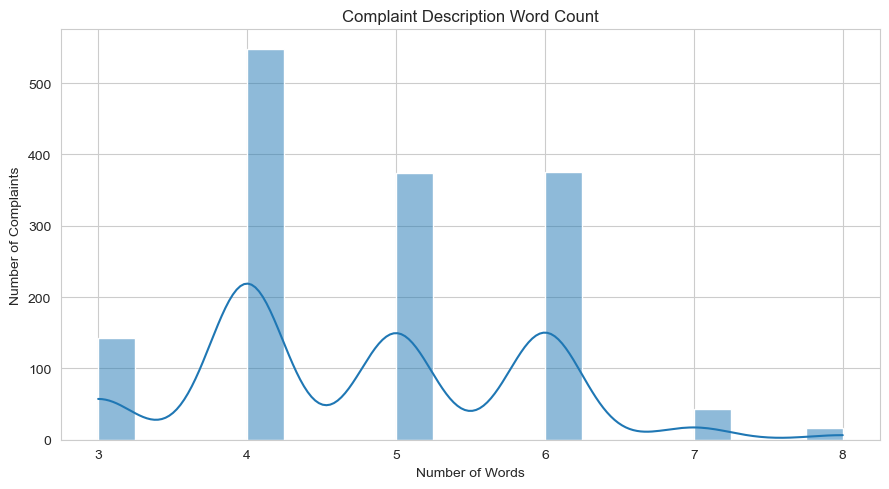

In [34]:

data["word_count"] = data["description_clean"].apply(
    lambda x: len(x.split())
)

print("Average words per complaint:",
      round(data["word_count"].mean(), 2))

print("Maximum words:",
      data["word_count"].max())

print("Minimum words:",
      data["word_count"].min())

plt.figure(figsize=(9, 5))

sns.histplot(data["word_count"], bins=20, kde=True)

plt.title("Complaint Description Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

In [35]:
print("Category Distribution:")
display(data["category"].value_counts())

print("\nPriority Distribution:")
display(data["priority"].value_counts())

Category Distribution:


category
Electrical    269
Cleaning      252
IT/Network    251
Plumbing      239
Civil         212
Furniture     165
Security      112
Name: count, dtype: int64


Priority Distribution:


priority
Medium    640
High      457
Low       403
Name: count, dtype: int64

In [36]:
repeated = (
    data.groupby("description_clean")
    .agg(
        total_records=("complaint_id", "count"),
        categories=("category", "nunique"),
        priorities=("priority", "nunique")
    )
    .sort_values("total_records", ascending=False)
)

display(repeated.head(15))

print("Repeated description groups:",
      (repeated["total_records"] > 1).sum())

print("Descriptions with conflicting categories:",
      (repeated["categories"] > 1).sum())

print("Descriptions with conflicting priorities:",
      (repeated["priorities"] > 1).sum())

,total_records,categories,priorities
description_clean,,,
problem in the room please check,32,7,3
bad condition needs urgent attention,29,6,3
dust on tables and windows,22,1,2
mcb keeps tripping again and again,21,1,3
server room ac is not working,21,1,2
wall is damaged,21,1,3
wi fi is not working,21,1,3
short circuit in room power tripped,20,1,2
dustbin is overflowing,20,1,3


Repeated description groups: 108
Descriptions with conflicting categories: 7
Descriptions with conflicting priorities: 105


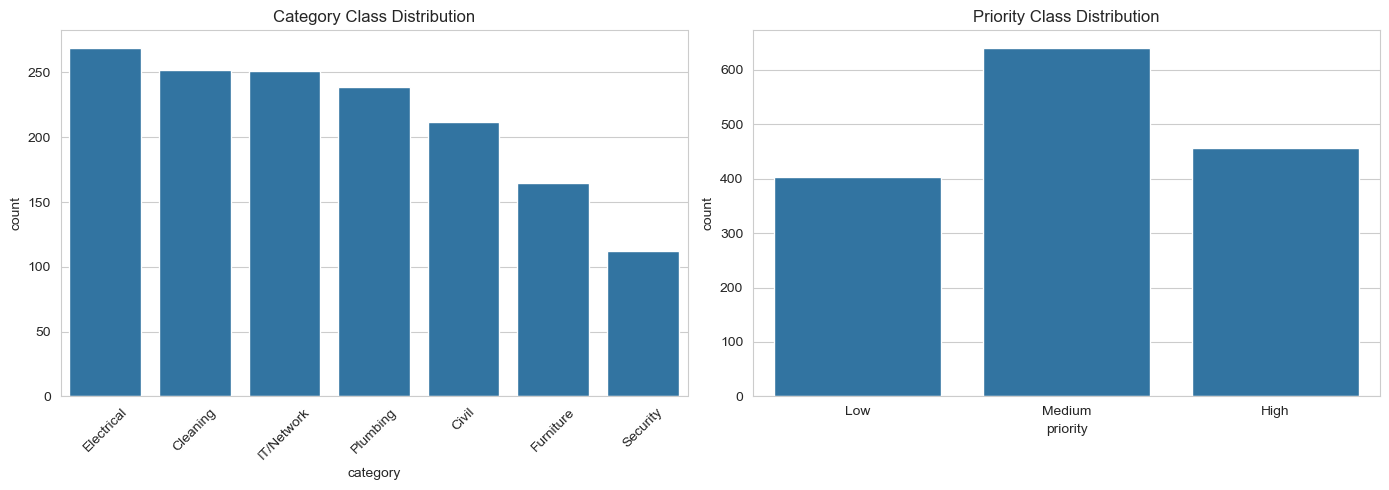

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=data, x="category",
              order=data["category"].value_counts().index,
              ax=axes[0])

axes[0].set_title("Category Class Distribution")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=data, x="priority",
              order=["Low", "Medium", "High"],
              ax=axes[1])

axes[1].set_title("Priority Class Distribution")

plt.tight_layout()
plt.show()

In [38]:
X = data["description_clean"]

y_category = data["category"]
y_priority = data["priority"]

print("Input Features:", X.shape)
print("Category Target:", y_category.shape)
print("Priority Target:", y_priority.shape)

print("\nCategory Classes:")
print(y_category.unique())

print("\nPriority Classes:")
print(y_priority.unique())

Input Features: (1500,)
Category Target: (1500,)
Priority Target: (1500,)

Category Classes:
['Cleaning' 'Plumbing' 'Furniture' 'Security' 'Electrical' 'IT/Network'
 'Civil']

Priority Classes:
['Medium' 'Low' 'High']


In [40]:
category_conflicts = (
    data.groupby("description_clean")
    .filter(lambda x: x["category"].nunique() > 1)
)

print("Total conflicting category records:", len(category_conflicts))

display(
    category_conflicts[
        ["description_clean", "description",
         "category", "priority", "location"]
    ].sort_values("description_clean").head(30)
)

Total conflicting category records: 111


,description_clean,description,category,priority,location
744,bad condition needs urgent attention,"Bad condition, needs urgent attention",IT/Network,Low,Laboratory Block
654,bad condition needs urgent attention,"Bad condition, needs urgent attention",Cleaning,Medium,Hostel C
500,bad condition needs urgent attention,"Bad condition, needs urgent attention",IT/Network,Medium,Computer Center
665,bad condition needs urgent attention,"Bad condition, needs urgent attention",Furniture,Medium,Hostel C
687,bad condition needs urgent attention,"Bad condition, needs urgent attention",IT/Network,High,Computer Center
476,bad condition needs urgent attention,"Bad condition, needs urgent attention",Cleaning,Medium,Academic Block
441,bad condition needs urgent attention,"Bad condition, needs urgent attention",Electrical,Low,Cafeteria
726,bad condition needs urgent attention,"Bad condition, needs urgent attention",Cleaning,Medium,Hostel A
358,bad condition needs urgent attention,"Bad condition, needs urgent attention",IT/Network,Medium,Computer Center
751,bad condition needs urgent attention,"Bad condition, needs urgent attention",IT/Network,Medium,Laboratory Block


In [41]:
priority_conflicts = (
    data.groupby("description_clean")
    .filter(lambda x: x["priority"].nunique() > 1)
)

print("Total conflicting priority records:", len(priority_conflicts))

display(
    priority_conflicts[
        ["description_clean", "description",
         "category", "priority", "location"]
    ].sort_values("description_clean").head(30)
)

Total conflicting priority records: 1465


,description_clean,description,category,priority,location
1072,ac is not cooling,AC is not cooling,Electrical,Low,Hostel B
177,ac is not cooling,AC is not cooling,Electrical,High,Library
1488,ac is not cooling,AC is not cooling,Electrical,Medium,Parking Area
1245,ac is not cooling,AC is not cooling,Electrical,Low,Hostel B
920,ac is not cooling,AC is not cooling,Electrical,Low,Hostel A
1138,ac is not cooling,AC is not cooling,Electrical,Low,Academic Block
565,ac is not cooling,AC is not cooling,Electrical,Low,Academic Block
1353,ac is not cooling,AC is not cooling,Electrical,High,Administrative Block
730,ac is not cooling,AC is not cooling,Electrical,Medium,Hostel B
247,ac is not cooling,AC is not cooling,Electrical,Low,Main Gate


In [42]:
print("Category consistency:")
display(
    data.groupby("description_clean")["category"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("Priority consistency:")
display(
    data.groupby("description_clean")["priority"]
    .nunique()
    .value_counts()
    .sort_index()
)

Category consistency:


category
1    101
2      2
3      3
6      1
7      1
Name: count, dtype: int64

Priority consistency:


priority
1     3
2    42
3    63
Name: count, dtype: int64

In [43]:
category_location = (
    data.groupby(["description_clean", "location"])
    .agg(
        total_records=("complaint_id", "count"),
        category_count=("category", "nunique"),
        priority_count=("priority", "nunique")
    )
    .reset_index()
)

print("Category conflicts by description + location:")

display(
    category_location[
        category_location["category_count"] > 1
    ].sort_values("total_records", ascending=False).head(20)
)

print(
    "Total conflicting description-location groups:",
    (category_location["category_count"] > 1).sum()
)

Category conflicts by description + location:


,description_clean,location,total_records,category_count,priority_count
8,bad condition needs urgent attention,Academic Block,7,4,3
443,problem in the room please check,Hostel B,6,4,2
442,problem in the room please check,Hostel A,5,3,3
670,water on the floor near the washroom,Hostel B,5,2,2
438,problem in the room please check,Academic Block,4,3,3
11,bad condition needs urgent attention,Computer Center,4,2,2
444,problem in the room please check,Hostel C,4,3,3
439,problem in the room please check,Administrative Block,4,3,2
13,bad condition needs urgent attention,Hostel B,3,3,3
14,bad condition needs urgent attention,Hostel C,3,3,2


Total conflicting description-location groups: 22


In [44]:
print("Priority conflicts by description + location:")

display(
    category_location[
        category_location["priority_count"] > 1
    ].sort_values("total_records", ascending=False).head(20)
)

print(
    "Total conflicting priority groups:",
    (category_location["priority_count"] > 1).sum()
)

Priority conflicts by description + location:


,description_clean,location,total_records,category_count,priority_count
363,no water supply since morning,Hostel B,11,1,2
181,dust on tables and windows,Hostel B,8,1,2
377,paani nahi aa raha tap mein,Hostel C,8,1,2
656,water cooler is not working,Hostel B,8,1,2
101,complete network outage in the lab,Academic Block,8,1,2
386,pankha nahi chal raha,Academic Block,7,1,3
522,sewage smell near the building,Hostel C,7,1,2
242,food waste lying near the dustbin,Hostel B,7,1,3
539,shower is leaking continuously,Hostel A,7,1,2
8,bad condition needs urgent attention,Academic Block,7,4,3


Total conflicting priority groups: 262


In [45]:
display(
    pd.crosstab(
        data["category"],
        data["priority"],
        normalize="index"
    ).round(3) * 100
)

priority,High,Low,Medium
category,,,
Civil,33.0,26.9,40.1
Cleaning,17.5,36.1,46.4
Electrical,34.6,26.4,39.0
Furniture,14.5,37.0,48.5
IT/Network,34.3,23.1,42.6
Plumbing,37.7,20.9,41.4
Security,44.6,13.4,42.0


In [57]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Input features
X = data[["description_clean", "location"]].copy()

# Target variable
y = data["category"].copy()

# Encode target labels for XGBoost
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Libraries imported successfully!")
print("Dataset Shape:", X.shape)
print("Category Classes:", label_encoder.classes_)

Libraries imported successfully!
Dataset Shape: (1500, 2)
Category Classes: ['Civil' 'Cleaning' 'Electrical' 'Furniture' 'IT/Network' 'Plumbing'
 'Security']


In [58]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y_encoded,
        groups=data["description_clean"]
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

y_train_encoded = y_encoded[train_idx]
y_test_encoded = y_encoded[test_idx]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Classes:")
display(y_train.value_counts())

print("\nTesting Classes:")
display(y_test.value_counts())

print("\nClasses missing from training:",
      set(label_encoder.classes_) - set(y_train.unique()))

Training Records: 1161
Testing Records: 339

Training Classes:


category
Cleaning      225
Electrical    211
IT/Network    194
Plumbing      163
Civil         152
Furniture     119
Security       97
Name: count, dtype: int64


Testing Classes:


category
Plumbing      76
Civil         60
Electrical    58
IT/Network    57
Furniture     46
Cleaning      27
Security      15
Name: count, dtype: int64


Classes missing from training: set()


In [59]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                ngram_range=(1, 2),
                max_features=3000
            ),
            "description_clean"
        ),
        (
            "location",
            OneHotEncoder(handle_unknown="ignore"),
            ["location"]
        )
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, classifier in models.items():

    print(f"\nTraining {name}...")

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    if name == "XGBoost":
        model.fit(X_train, y_train_encoded)
    else:
        model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} training completed!")

print("\nAll three models trained successfully!")


Training Logistic Regression...
Logistic Regression training completed!

Training Random Forest...
Random Forest training completed!

Training XGBoost...
XGBoost training completed!

All three models trained successfully!



Logistic Regression
              precision    recall  f1-score   support

       Civil       0.20      0.18      0.19        60
    Cleaning       0.45      0.74      0.56        27
  Electrical       0.38      0.48      0.43        58
   Furniture       0.24      0.35      0.28        46
  IT/Network       0.61      0.44      0.51        57
    Plumbing       0.62      0.43      0.51        76
    Security       0.00      0.00      0.00        15

    accuracy                           0.39       339
   macro avg       0.36      0.38      0.36       339
weighted avg       0.41      0.39      0.39       339



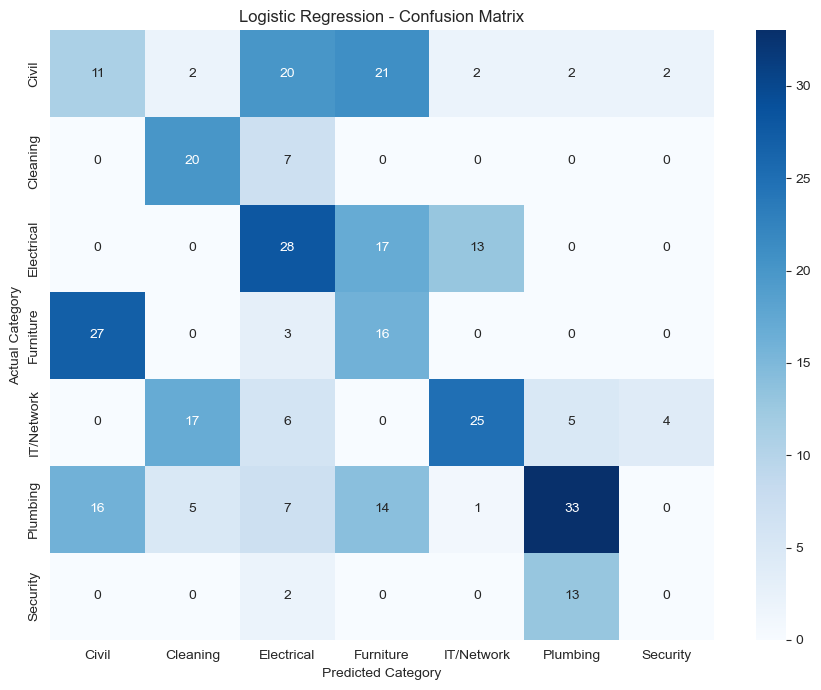


Random Forest
              precision    recall  f1-score   support

       Civil       0.00      0.00      0.00        60
    Cleaning       0.00      0.00      0.00        27
  Electrical       0.29      0.48      0.36        58
   Furniture       0.20      0.26      0.23        46
  IT/Network       0.39      0.21      0.27        57
    Plumbing       1.00      0.38      0.55        76
    Security       0.00      0.00      0.00        15

    accuracy                           0.24       339
   macro avg       0.27      0.19      0.20       339
weighted avg       0.37      0.24      0.26       339



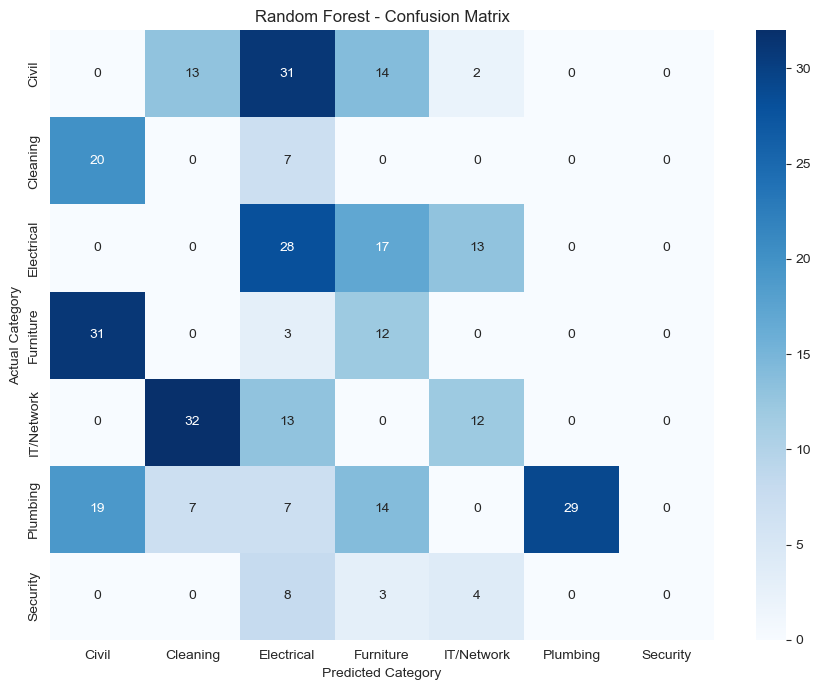


XGBoost
              precision    recall  f1-score   support

       Civil       0.12      0.23      0.16        60
    Cleaning       0.77      0.63      0.69        27
  Electrical       0.35      0.38      0.37        58
   Furniture       0.30      0.26      0.28        46
  IT/Network       0.56      0.61      0.59        57
    Plumbing       1.00      0.47      0.64        76
    Security       0.00      0.00      0.00        15

    accuracy                           0.40       339
   macro avg       0.44      0.37      0.39       339
weighted avg       0.50      0.40      0.43       339



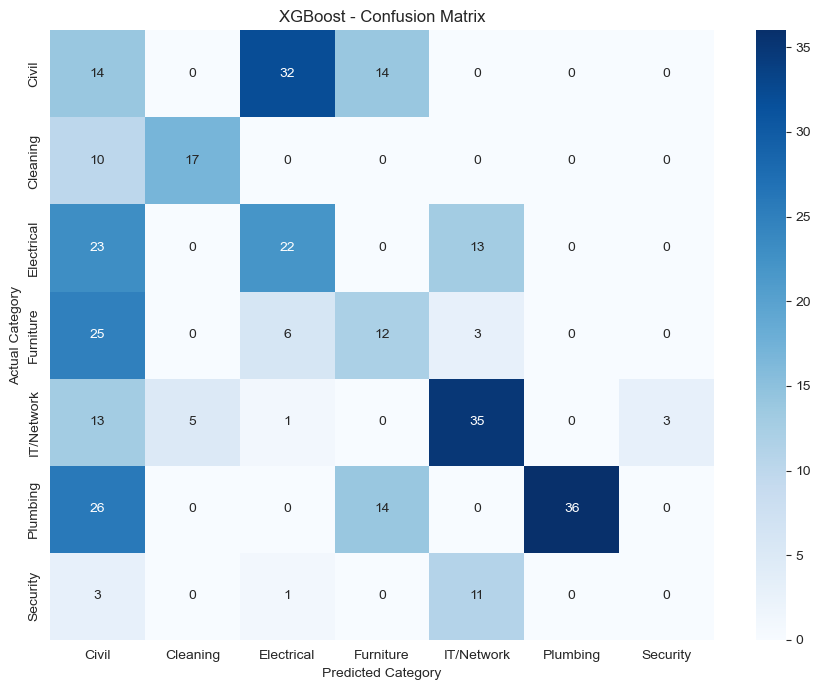


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.4012,0.4450,0.3701,0.3902
1,Logistic Regression,0.3923,0.3585,0.3754,0.3552
2,Random Forest,0.2389,0.2680,0.1908,0.2018


In [60]:
results = []

for name, model in trained_models.items():

    # Generate predictions
    predictions = model.predict(X_test)

    # Convert XGBoost numeric predictions into category names
    if name == "XGBoost":
        y_pred = label_encoder.inverse_transform(
            predictions.astype(int)
        )
    else:
        y_pred = predictions

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=label_encoder.classes_,
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=label_encoder.classes_
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")
    plt.tight_layout()
    plt.show()


# Final comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")

display(results_df.round(4))

In [61]:
from sklearn.metrics import classification_report

xgb_predictions = trained_models["XGBoost"].predict(X_test)

xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions.astype(int)
)

print(classification_report(
    y_test,
    xgb_predictions,
    zero_division=0
))

              precision    recall  f1-score   support

       Civil       0.12      0.23      0.16        60
    Cleaning       0.77      0.63      0.69        27
  Electrical       0.35      0.38      0.37        58
   Furniture       0.30      0.26      0.28        46
  IT/Network       0.56      0.61      0.59        57
    Plumbing       1.00      0.47      0.64        76
    Security       0.00      0.00      0.00        15

    accuracy                           0.40       339
   macro avg       0.44      0.37      0.39       339
weighted avg       0.50      0.40      0.43       339



In [62]:
error_analysis = X_test.copy()

error_analysis["Actual_Category"] = y_test
error_analysis["Predicted_Category"] = xgb_predictions

wrong_predictions = error_analysis[
    error_analysis["Actual_Category"] !=
    error_analysis["Predicted_Category"]
]

print("Total Incorrect Predictions:", len(wrong_predictions))

display(wrong_predictions.head(30))

Total Incorrect Predictions: 203


,description_clean,location,Actual_Category,Predicted_Category
1,problem in the room please check,Hostel A,Plumbing,Civil
7,cctv camera is not working,Parking Area,Security,IT/Network
8,projector socket is loose,Library,Electrical,Civil
19,shelf is falling off the wall,Hostel C,Furniture,Civil
21,shelf is falling off the wall,Hostel B,Furniture,Civil
50,kursi toot gayi hai,Laboratory Block,Furniture,IT/Network
54,problem in the room please check,Hostel A,IT/Network,Civil
58,shelf is falling off the wall,Academic Block,Furniture,Civil
76,shower is leaking continuously,Hostel C,Plumbing,Civil
84,kursi toot gayi hai,Hostel C,Furniture,Electrical


,Feature,Importance
232,text__lan port,0.039240
459,text__washroom flush,0.035571
307,text__off the,0.026284
282,text__near gate,0.024944
396,text__staircase,0.020670
80,text__cooler,0.018721
475,text__wi fi,0.017563
216,text__issue,0.017434
285,text__needs cleaning,0.011948
95,text__daraar aa,0.011594


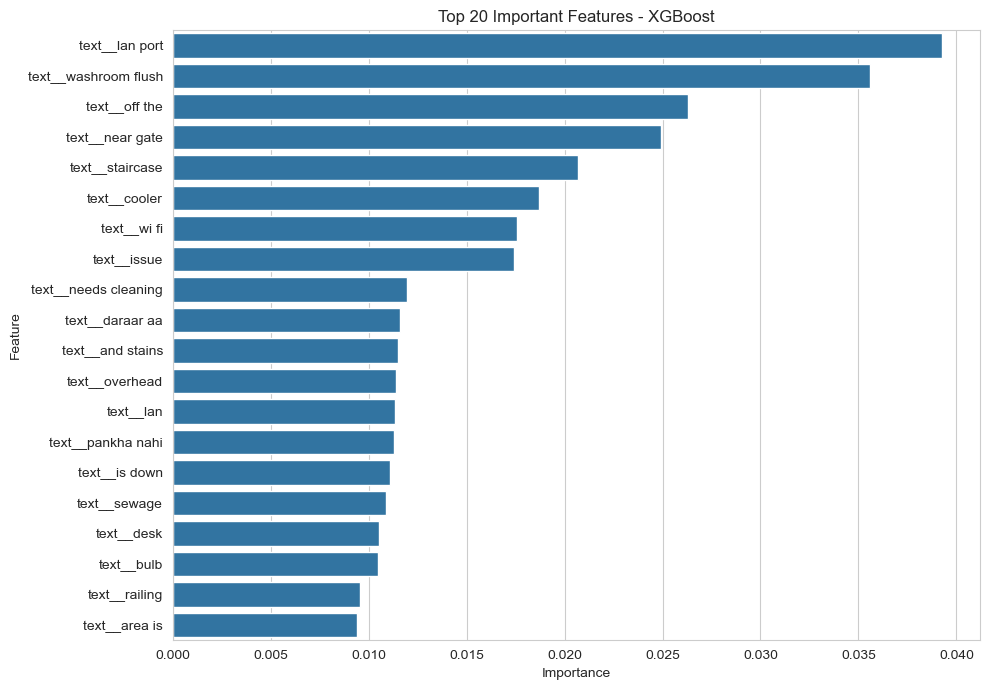

In [63]:
xgb_classifier = trained_models["XGBoost"].named_steps["classifier"]

feature_names = (
    trained_models["XGBoost"]
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_classifier.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(20))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features - XGBoost")
plt.tight_layout()
plt.show()

In [64]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

improved_preprocessor = ColumnTransformer(
    transformers=[
        (
            "word_tfidf",
            TfidfVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                sublinear_tf=True,
                max_features=5000
            ),
            "description_clean"
        ),
        (
            "char_tfidf",
            TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(2, 5),
                sublinear_tf=True,
                max_features=3000
            ),
            "description_clean"
        ),
        (
            "location",
            OneHotEncoder(handle_unknown="ignore"),
            ["location"]
        )
    ]
)

print("Improved preprocessing pipeline ready!")

Improved preprocessing pipeline ready!


In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

improved_models = {
    "Improved Logistic Regression": LogisticRegression(
        C=2,
        max_iter=3000,
        class_weight="balanced"
    ),

    "Improved Random Forest": RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Improved XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}

improved_trained_models = {}

for name, classifier in improved_models.items():

    print(f"\nTraining {name}...")

    model = Pipeline([
        ("preprocessor", improved_preprocessor),
        ("classifier", classifier)
    ])

    if "XGBoost" in name:
        model.fit(X_train, y_train_encoded)
    else:
        model.fit(X_train, y_train)

    improved_trained_models[name] = model

    print(f"{name} completed!")


Training Improved Logistic Regression...
Improved Logistic Regression completed!

Training Improved Random Forest...
Improved Random Forest completed!

Training Improved XGBoost...
Improved XGBoost completed!


In [66]:
improved_results = []

for name, model in improved_trained_models.items():

    predictions = model.predict(X_test)

    if "XGBoost" in name:
        predictions = label_encoder.inverse_transform(
            predictions.astype(int)
        )

    improved_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
    })

improved_results_df = pd.DataFrame(improved_results)

display(
    improved_results_df.sort_values(
        "F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Improved Random Forest,0.3805,0.3959,0.3609,0.3592
0,Improved Logistic Regression,0.3481,0.3303,0.3396,0.3177
2,Improved XGBoost,0.2271,0.1688,0.2448,0.1939


In [67]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

best_model = improved_trained_models["Improved Random Forest"]

rf_predictions = best_model.predict(X_test)

print("Classification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, rf_predictions)
cm_df = pd.DataFrame(
    cm,
    index=best_model.classes_,
    columns=best_model.classes_
)

display(cm_df)

Classification Report:
              precision    recall  f1-score   support

       Civil       0.19      0.20      0.20        60
    Cleaning       0.53      0.74      0.62        27
  Electrical       0.44      0.48      0.46        58
   Furniture       0.15      0.26      0.19        46
  IT/Network       0.47      0.37      0.41        57
    Plumbing       1.00      0.47      0.64        76
    Security       0.00      0.00      0.00        15

    accuracy                           0.38       339
   macro avg       0.40      0.36      0.36       339
weighted avg       0.47      0.38      0.40       339

Confusion Matrix:


,Civil,Cleaning,Electrical,Furniture,IT/Network,Plumbing,Security
Civil,12,0,14,34,0,0,0
Cleaning,0,20,7,0,0,0,0
Electrical,0,0,28,17,13,0,0
Furniture,18,0,3,12,0,0,13
IT/Network,14,18,4,0,21,0,0
Plumbing,19,0,7,14,0,36,0
Security,0,0,1,3,11,0,0


In [68]:
# Check category inconsistencies in the dataset

label_check = (
    data.groupby("description_clean")
    .agg(
        total_records=("category", "size"),
        unique_categories=("category", "nunique"),
        categories=("category", lambda x: list(x.unique()))
    )
    .reset_index()
)

# Show descriptions having multiple category labels
conflicting_labels = label_check[
    label_check["unique_categories"] > 1
].sort_values("total_records", ascending=False)

print("Total conflicting descriptions:", len(conflicting_labels))

display(conflicting_labels.head(20))

Total conflicting descriptions: 7


,description_clean,total_records,unique_categories,categories
67,problem in the room please check,32,7,"[Plumbing, IT/Network, Electrical, Cleaning, Civil, Furniture, Security]"
1,bad condition needs urgent attention,29,6,"[Plumbing, IT/Network, Cleaning, Electrical, Furniture, Civil]"
100,water on the floor near the washroom,16,3,"[Cleaning, Plumbing, Civil]"
46,lab ac and system both not working,10,2,"[IT/Network, Electrical]"
9,cable is hanging and wire is cut,10,2,"[Electrical, IT/Network]"
39,gate is damaged and not locking,9,3,"[Furniture, Civil, Security]"
23,door is not closing properly,5,3,"[Furniture, Civil, Security]"


In [69]:
print("Training category distribution:")
display(y_train.value_counts().to_frame("Training Records"))

print("Testing category distribution:")
display(y_test.value_counts().to_frame("Testing Records"))

Training category distribution:


,Training Records
category,
Cleaning,225
Electrical,211
IT/Network,194
Plumbing,163
Civil,152
Furniture,119
Security,97


Testing category distribution:


,Testing Records
category,
Plumbing,76
Civil,60
Electrical,58
IT/Network,57
Furniture,46
Cleaning,27
Security,15


In [70]:
# Detailed inspection of conflicting descriptions

for description in conflicting_labels["description_clean"]:

    print("\n" + "=" * 80)
    print("DESCRIPTION:", description)

    subset = data[data["description_clean"] == description]

    print("\nCategory distribution:")
    display(subset["category"].value_counts().to_frame("Count"))

    print("\nLocation and category:")
    display(
        pd.crosstab(
            subset["location"],
            subset["category"]
        )
    )


DESCRIPTION: problem in the room please check

Category distribution:


,Count
category,
Electrical,8
Plumbing,7
Cleaning,7
IT/Network,4
Furniture,3
Civil,2
Security,1



Location and category:


category,Civil,Cleaning,Electrical,Furniture,IT/Network,Plumbing,Security
location,,,,,,,
Academic Block,1,1,2,0,0,0,0
Administrative Block,0,0,2,0,1,0,1
Cafeteria,0,0,1,0,0,0,0
Computer Center,0,0,0,0,1,0,0
Hostel A,0,0,0,2,1,2,0
Hostel B,1,1,1,0,0,3,0
Hostel C,0,2,1,0,0,1,0
Library,0,1,0,1,1,0,0
Parking Area,0,1,0,0,0,1,0



DESCRIPTION: bad condition needs urgent attention

Category distribution:


,Count
category,
IT/Network,9
Cleaning,8
Electrical,5
Furniture,4
Civil,2
Plumbing,1


... (18 outputs left out)


DESCRIPTION: door is not closing properly

Category distribution:


,Count
category,
Furniture,2
Civil,2
Security,1



Location and category:


category,Civil,Furniture,Security
location,,,
Hostel A,1,0,0
Hostel B,1,0,1
Hostel C,0,1,0
Parking Area,0,1,0


In [71]:
# Inspect all Security complaints

security_data = data[data["category"] == "Security"]

print("Total Security complaints:", len(security_data))

display(
    security_data[
        ["description", "description_clean", "location", "priority"]
    ].head(30)
)

print("\nMost common Security descriptions:")

display(
    security_data["description_clean"]
    .value_counts()
    .to_frame("Count")
    .head(20)
)

Total Security complaints: 112


,description,description_clean,location,priority
7,CCTV camera is not working,cctv camera is not working,Parking Area,Low
9,Street light near gate is not working,street light near gate is not working,Library,High
15,Parking area is poorly lit,parking area is poorly lit,Hostel C,High
20,Raat ko guard nahi tha,raat ko guard nahi tha,Hostel B,Medium
33,Raat ko guard nahi tha,raat ko guard nahi tha,Parking Area,Medium
35,Raat ko guard nahi tha,raat ko guard nahi tha,Library,High
39,Speed breaker paint faded near gate,speed breaker paint faded near gate,Hostel A,Low
68,Biometric entry system not working,biometric entry system not working,Sports Complex,Low
72,Raat ko guard nahi tha,raat ko guard nahi tha,Sports Complex,High
77,Speed breaker paint faded near gate,speed breaker paint faded near gate,Library,Low



Most common Security descriptions:


,Count
description_clean,
security gate issue,12
cctv camera is not working,11
bike stolen from parking,11
visitor register not maintained,11
parking area is poorly lit,10
raat ko guard nahi tha,10
speed breaker paint faded near gate,8
biometric entry system not working,7
street light near gate is not working,7


In [72]:
# Analyze Security prediction errors

security_analysis = pd.DataFrame({
    "description": X_test["description_clean"].values,
    "location": X_test["location"].values,
    "actual_category": y_test.values,
    "predicted_category": rf_predictions
})

security_errors = security_analysis[
    security_analysis["actual_category"] == "Security"
].copy()

print("Total Security test records:", len(security_errors))

print("\nPredicted categories for actual Security complaints:")
display(
    security_errors["predicted_category"]
    .value_counts()
    .to_frame("Count")
)

print("\nSecurity misclassification examples:")
display(
    security_errors[
        security_errors["predicted_category"] != "Security"
    ]
)

Total Security test records: 15

Predicted categories for actual Security complaints:


,Count
predicted_category,
IT/Network,11
Furniture,3
Electrical,1



Security misclassification examples:


,description,location,actual_category,predicted_category
1,cctv camera is not working,Parking Area,Security,IT/Network
27,cctv camera is not working,Hostel C,Security,IT/Network
50,cctv camera is not working,Hostel B,Security,IT/Network
72,cctv camera is not working,Hostel C,Security,IT/Network
102,cctv camera is not working,Parking Area,Security,IT/Network
108,cctv camera is not working,Hostel A,Security,IT/Network
117,cctv camera is not working,Hostel B,Security,IT/Network
119,cctv camera is not working,Sports Complex,Security,IT/Network
150,cctv camera is not working,Hostel C,Security,IT/Network
162,emergency exit is blocked,Main Gate,Security,Furniture


In [73]:
# Check CCTV and emergency-exit labels in the full dataset

check_descriptions = [
    "cctv camera is not working",
    "emergency exit is blocked",
    "problem in the room please check"
]

for desc in check_descriptions:
    print("\nDescription:", desc)

    subset = data[data["description_clean"] == desc]

    display(
        subset["category"]
        .value_counts()
        .to_frame("Count")
    )

    print("Total records:", len(subset))


Description: cctv camera is not working


,Count
category,
Security,11


Total records: 11

Description: emergency exit is blocked


,Count
category,
Security,3


Total records: 3

Description: problem in the room please check


,Count
category,
Electrical,8
Plumbing,7
Cleaning,7
IT/Network,4
Furniture,3
Civil,2
Security,1


Total records: 32


In [74]:
# Check whether Security test descriptions were seen during training

train_descriptions = set(X_train["description_clean"])

security_errors["seen_in_training"] = (
    security_errors["description"].isin(train_descriptions)
)

display(
    security_errors[
        ["description", "actual_category",
         "predicted_category", "seen_in_training"]
    ]
)


,description,actual_category,predicted_category,seen_in_training
1,cctv camera is not working,Security,IT/Network,False
27,cctv camera is not working,Security,IT/Network,False
50,cctv camera is not working,Security,IT/Network,False
72,cctv camera is not working,Security,IT/Network,False
102,cctv camera is not working,Security,IT/Network,False
108,cctv camera is not working,Security,IT/Network,False
117,cctv camera is not working,Security,IT/Network,False
119,cctv camera is not working,Security,IT/Network,False
150,cctv camera is not working,Security,IT/Network,False
162,emergency exit is blocked,Security,Furniture,False


In [75]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Create a stratified random split
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a fresh copy of the existing model
random_split_model = clone(
    improved_trained_models["Improved Random Forest"]
)

# Train the model
random_split_model.fit(X_train_random, y_train_random)

# Make predictions
random_predictions = random_split_model.predict(X_test_random)

# Evaluate
print("Random Split Accuracy:",
      accuracy_score(y_test_random, random_predictions))

print("Random Split Macro F1:",
      f1_score(y_test_random, random_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test_random,
    random_predictions,
    zero_division=0
))

# Check Security performance
security_random = pd.DataFrame({
    "description": X_test_random["description_clean"],
    "actual": y_test_random,
    "predicted": random_predictions
})

print("\nSecurity predictions:")
display(
    security_random[
        security_random["actual"] == "Security"
    ]
)

Random Split Accuracy: 0.9633333333333334
Random Split Macro F1: 0.9670792578606536

Classification Report:
              precision    recall  f1-score   support

       Civil       1.00      0.95      0.98        43
    Cleaning       0.96      0.94      0.95        50
  Electrical       0.91      0.98      0.95        54
   Furniture       0.97      0.97      0.97        33
  IT/Network       0.96      0.98      0.97        50
    Plumbing       0.98      0.94      0.96        48
    Security       1.00      1.00      1.00        22

    accuracy                           0.96       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.96      0.96      0.96       300


Security predictions:


,description,actual,predicted
717,parking area is poorly lit,Security,Security
202,security gate issue,Security,Security
1450,street light near gate is not working,Security,Security
1288,unknown persons entering without id check,Security,Security
378,bike stolen from parking,Security,Security
733,fire extinguisher is expired,Security,Security
484,broken boundary wall near the gate,Security,Security
1068,security gate issue,Security,Security
925,security gate issue,Security,Security
502,security gate issue,Security,Security


In [76]:
# Measure description overlap between training and testing

train_texts = set(X_train_random["description_clean"])

test_seen = X_test_random["description_clean"].isin(train_texts)

print("Total test records:", len(X_test_random))
print("Previously seen descriptions:", test_seen.sum())
print("Unseen descriptions:", (~test_seen).sum())

print(
    "Seen description percentage:",
    round(test_seen.mean() * 100, 2), "%"
)

print(
    "Unseen description percentage:",
    round((~test_seen).mean() * 100, 2), "%"
)

Total test records: 300
Previously seen descriptions: 300
Unseen descriptions: 0
Seen description percentage: 100.0 %
Unseen description percentage: 0.0 %


In [77]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(X, y, groups=data["description_clean"]),
    start=1
):
    X_tr = X.iloc[train_idx]
    X_te = X.iloc[test_idx]

    y_tr = y.iloc[train_idx]
    y_te = y.iloc[test_idx]

    # Check description overlap
    overlap = set(X_tr["description_clean"]) & set(
        X_te["description_clean"]
    )

    print(f"\nFold {fold}")
    print("Training records:", len(train_idx))
    print("Testing records:", len(test_idx))
    print("Description overlap:", len(overlap))
    print("Training classes:", y_tr.nunique())
    print("Testing classes:", y_te.nunique())
    


Fold 1
Training records: 1160
Testing records: 340
Description overlap: 0
Training classes: 7
Testing classes: 7

Fold 2
Training records: 1214
Testing records: 286
Description overlap: 0
Training classes: 7
Testing classes: 7

Fold 3
Training records: 1227
Testing records: 273
Description overlap: 0
Training classes: 7
Testing classes: 7

Fold 4
Training records: 1191
Testing records: 309
Description overlap: 0
Training classes: 7
Testing classes: 7

Fold 5
Training records: 1208
Testing records: 292
Description overlap: 0
Training classes: 7
Testing classes: 7


In [78]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(X, y, groups=data["description_clean"]),
    start=1
):

    X_tr = X.iloc[train_idx]
    X_te = X.iloc[test_idx]

    y_tr = y.iloc[train_idx]
    y_te = y.iloc[test_idx]

    # Fresh model for every fold
    model = clone(
        improved_trained_models["Improved Random Forest"]
    )

    model.fit(X_tr, y_tr)

    predictions = model.predict(X_te)

    cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_te, predictions),
        "Precision": precision_score(
            y_te, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_te, predictions, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_te, predictions, average="macro", zero_division=0
        )
    })

cv_results_df = pd.DataFrame(cv_results)

print("5-Fold Cross Validation Results:")
display(cv_results_df.round(4))

print("\nAverage Performance:")
display(
    cv_results_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(4)
)

5-Fold Cross Validation Results:


,Fold,Accuracy,Precision,Recall,F1 Score
0,1,0.3500,0.2946,0.4426,0.2848
1,2,0.3531,0.5113,0.4545,0.4097
2,3,0.3370,0.4649,0.3490,0.3656
3,4,0.4790,0.4537,0.4444,0.4253
4,5,0.3219,0.2924,0.3662,0.3095



Average Performance:


,Accuracy,Precision,Recall,F1 Score
mean,0.3682,0.4034,0.4113,0.3590
std,0.0631,0.1026,0.0496,0.0612


In [79]:

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models_to_compare = {
    "Logistic Regression": improved_trained_models["Improved Logistic Regression"],
    "Random Forest": improved_trained_models["Improved Random Forest"],
    "XGBoost": improved_trained_models["Improved XGBoost"]
}

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

comparison_results = []

for model_name, original_model in models_to_compare.items():

    for fold, (train_idx, test_idx) in enumerate(
        sgkf.split(X, y, groups=data["description_clean"]),
        start=1
    ):

        X_tr = X.iloc[train_idx]
        X_te = X.iloc[test_idx]
        y_tr = y.iloc[train_idx]
        y_te = y.iloc[test_idx]

        model = clone(original_model)

        if model_name == "XGBoost":
            y_tr_encoded = label_encoder.transform(y_tr)
            model.fit(X_tr, y_tr_encoded)

            pred_encoded = model.predict(X_te).astype(int)
            predictions = label_encoder.inverse_transform(pred_encoded)
        else:
            model.fit(X_tr, y_tr)
            predictions = model.predict(X_te)

        comparison_results.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy_score(y_te, predictions),
            "Precision": precision_score(
                y_te, predictions, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_te, predictions, average="macro", zero_division=0
            ),
            "F1 Score": f1_score(
                y_te, predictions, average="macro", zero_division=0
            )
        })

comparison_df = pd.DataFrame(comparison_results)

print("Individual Fold Results:")
display(comparison_df.round(4))

print("\nAverage Model Performance:")

model_summary = (
    comparison_df.groupby("Model")
    .agg({
        "Accuracy": ["mean", "std"],
        "Precision": ["mean", "std"],
        "Recall": ["mean", "std"],
        "F1 Score": ["mean", "std"]
    })
)

display(model_summary.round(4))



Individual Fold Results:


,Model,Fold,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1,0.4176,0.4591,0.4642,0.3726
1,Logistic Regression,2,0.4371,0.5555,0.5039,0.4448
2,Logistic Regression,3,0.2711,0.3573,0.3585,0.3173
3,Logistic Regression,4,0.5663,0.6382,0.5787,0.5656
4,Logistic Regression,5,0.4521,0.4873,0.4547,0.4577
5,Random Forest,1,0.3500,0.2946,0.4426,0.2848
6,Random Forest,2,0.3531,0.5113,0.4545,0.4097
7,Random Forest,3,0.3370,0.4649,0.3490,0.3656
8,Random Forest,4,0.4790,0.4537,0.4444,0.4253
9,Random Forest,5,0.3219,0.2924,0.3662,0.3095



Average Model Performance:


Accuracy         Precision          Recall          \
                        mean     std      mean     std    mean     std   
Model                                                                    
Logistic Regression   0.4288  0.1055    0.4995  0.1053  0.4720  0.0801   
Random Forest         0.3682  0.0631    0.4034  0.1026  0.4113  0.0496   
XGBoost               0.3095  0.0755    0.3268  0.1374  0.3292  0.0699   

                    F1 Score          
                        mean     std  
Model                                 
Logistic Regression   0.4316  0.0940  
Random Forest         0.3590  0.0612  
XGBoost               0.2952  0.0890

In [80]:

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.metrics import classification_report
import pandas as pd

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store predictions from all five validation folds
all_actual = []
all_predictions = []

logistic_model = improved_trained_models[
    "Improved Logistic Regression"
]

for train_idx, test_idx in sgkf.split(
    X, y, groups=data["description_clean"]
):
    X_tr = X.iloc[train_idx]
    X_te = X.iloc[test_idx]

    y_tr = y.iloc[train_idx]
    y_te = y.iloc[test_idx]

    model = clone(logistic_model)
    model.fit(X_tr, y_tr)

    predictions = model.predict(X_te)

    all_actual.extend(y_te.tolist())
    all_predictions.extend(predictions.tolist())

print("Combined 5-Fold Classification Report:")

print(classification_report(
    all_actual,
    all_predictions,
    zero_division=0
))


Combined 5-Fold Classification Report:
              precision    recall  f1-score   support

       Civil       0.33      0.34      0.34       212
    Cleaning       0.43      0.44      0.44       252
  Electrical       0.42      0.50      0.46       269
   Furniture       0.44      0.51      0.47       165
  IT/Network       0.38      0.33      0.35       251
    Plumbing       0.54      0.44      0.48       239
    Security       0.58      0.52      0.55       112

    accuracy                           0.43      1500
   macro avg       0.45      0.44      0.44      1500
weighted avg       0.44      0.43      0.43      1500



In [81]:
# Inspect the Logistic Regression pipeline

best_lr = improved_trained_models[
    "Improved Logistic Regression"
]

print("Pipeline steps:")
print(best_lr.named_steps)

print("\nAvailable model parameters:")

for parameter in best_lr.get_params().keys():
    if "logistic" in parameter.lower():
        print(parameter)

Pipeline steps:
{'preprocessor': ColumnTransformer(transformers=[('word_tfidf',
                                 TfidfVectorizer(max_features=5000,
                                                 ngram_range=(1, 2),
                                                 sublinear_tf=True),
                                 'description_clean'),
                                ('char_tfidf',
                                 TfidfVectorizer(analyzer='char_wb',
                                                 max_features=3000,
                                                 ngram_range=(2, 5),
                                                 sublinear_tf=True),
                                 'description_clean'),
                                ('location',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['location'])]), 'classifier': LogisticRegression(C=2, class_weight='balanced', max_iter=3000)}

Available model parameters:


In [82]:

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV

# Parameter grid
param_grid = {
    "classifier__C": [0.1, 0.5, 1, 2, 5, 10],
    "classifier__class_weight": [
        "balanced",
        None
    ],
    "classifier__solver": ["lbfgs"]
}

# Group-based cross-validation
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=best_lr,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=sgkf,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Train and tune
grid_search.fit(
    X,
    y,
    groups=data["description_clean"]
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

print("\nBest Model:")
best_tuned_lr = grid_search.best_estimator_


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'classifier__C': 5, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Best Cross-Validation Macro F1:
0.4364

Best Model:


In [83]:

import os
import joblib
from sklearn.base import clone

# Prepare training features
X_final = data[["description_clean", "location"]].copy()

# Prepare target labels
y_category = data["category"]
y_priority = data["priority"]

# Train final category model on all available records
final_category_model = clone(best_tuned_lr)
final_category_model.fit(X_final, y_category)

# Train initial priority model
final_priority_model = clone(best_tuned_lr)
final_priority_model.fit(X_final, y_priority)

# Create model directory
os.makedirs("models", exist_ok=True)

# Save both models in one bundle
model_bundle = {
    "category_model": final_category_model,
    "priority_model": final_priority_model,
    "feature_columns": ["description_clean", "location"],
    "version": "1.0"
}

joblib.dump(
    model_bundle,
    "models/campus_maintenance_models.joblib"
)

print("Models trained and saved successfully!")

print("\nCategory classes:")
print(final_category_model.classes_)

print("\nPriority classes:")
print(final_priority_model.classes_)

print("\nSaved file:")
print(os.path.abspath("models/campus_maintenance_models.joblib"))


Models trained and saved successfully!

Category classes:
['Civil' 'Cleaning' 'Electrical' 'Furniture' 'IT/Network' 'Plumbing'
 'Security']

Priority classes:
['High' 'Low' 'Medium']

Saved file:
c:\Users\ASUS\Downloads\campus-maintenance-datascience-step1 (2)\campus-maintenance-main\ml-service\models\campus_maintenance_models.joblib
